# **Project 2: A Modular Approach to NBA All Star Selection**

November 2026

Matthew Rivers & Joseph Pascarella

The University of Tampa, FL

## **Introduction**

### **Project Overview**

In this project, we will take a modular approach to predicting all-star selections in the National Basketball Association (NBA). An 'all-star' is a player who has been selected to participate in the NBA All-Star Game, an annual exhibition match featuring the league's best players. The goal of this project is to build models to forecast which players are likely to be selected as all-stars based on performance and other related metrics. We will then evaluate each model and determine which one is best fit for predicting all-stars.

We will be comparing four classification models in this project:
- **Logistic Regression**
- **Random Forest**
- **Adaptive Boosting (AdaBoost)**
- **Extreme Gradient Boosting (XGBoost)**

These four models will be tuned with hyperparameter search and will be evaluated across train/test splits using accuracy, precision, recall, and F1 score. For this project specifically, the recall, precision, and F1 scores are extremely important as accuracy alone in this case can be misinterpreted (the amount of all-stars are a small fraction of the entire NBA player base, so accuracy alone will be offputting as a model that predicts 0 total all-stars would have a relatively high accuracy).
  
The main questions we are looking to address by the end of this project are as follows:

**1. Which model best seperates all-stars from other players?**

**2. Which statistics matter most in terms of all-star selections?**

**3. Where do the models disagree with actual selections, and why might this happen?**

### **Dataset & Features**

This project uses the "NBA Stats (1980-2024)" dataset by Rodney Carroll on Kaggle. It contains 20 files and 461 columns, including data obtained from Basketball-Reference around player/opponent statistics, team totals, all-star selections, and more NBA-relevant data. In this project we will only be using the following 3 files (features detailed below):

#### **Advanced Statistics** 
 - `seas_id`, `season`, `player_id`, `player`: ID columns that identify each player/season
 - `birth_year`, `age`: Player age (in a given season) and birth year 
 - `pos`: Player position (PG, SG, SF, PF, C)
 - `experience`: Number of years in the NBA
 - `lg`: League (NBA or ABA, we will later drop ABA to focus on NBA only)
 - `tm`: Team abbreviation (with TOT for a player's combined total across multiple teams if a player gets traded mid-season)
 - `g`: Games played
 - `mp`: Minutes played
 - `per`: Player Efficiency Rating (summarizes a player's statistical accomplishments in a single number, with positives and negatives weighted according to their impact on winning, league average is set to 15)
 - `ts_percent`: True Shooting Percentage (shooting efficiency that accounts for field goals, 3-point field goals, and free throws)
 - `x3p_ar`: 3-point attempt rate (the proportion of a player's field goal attempts that are 3-pointers)
 - `f_tr`: Free throw rate (the proportion of a player's field goal attempts that result in free throws made)
 - `orb_percent`: Offensive rebound percentage (the percentage of available offensive rebounds a player grabbed while on the floor)
 - `drb_percent`: Defensive rebound percentage (the percentage of available defensive rebounds a player grabbed while on the floor)
 - `trb_percent`: Total rebound percentage (the percentage of available rebounds a player grabbed while on the floor)
 - `ast_percent`: Assist percentage (the percentage of teammate field goals a player assisted while on the floor)
 - `stl_percent`: Steal percentage (the percentage of opponent possessions that end with a steal by the player while on the floor)
 - `blk_percent`: Block percentage (the percentage of opponent 2-point field goal attempts blocked by the player while on the floor)
 - `tov_percent`: Turnover percentage (the percentage of a player's possessions that end in a turnover)
 - `usg_percent`: Usage percentage (the percentage of team plays used by a player while on the floor)
 - `ows`, `dws`, `ws`: Offensive, Defensive, and Total Win Shares (an estimate of the number of wins contributed by a player)
 - `ws_48`: Win Shares per 48 minutes (an estimate of the number of wins contributed by a player per 48 minutes)
 - `obpm`, `dbpm`, `bpm`: Offensive, Defensive, and Total Box Plus/Minus (a box score-based metric that estimates a player's contribution to the team when on the floor)
 - `vorp`: Value Over Replacement Player (a box score-based metric that estimates a player's overall contribution to the team)
#### **Player Per Game Statistics**
(only including columns not already included in the Advanced Statistics file)
 - `gs`: Games started
 - `mp_per_game`: Minutes played per game
 - `fg_per_game`, `fga_per_game`, `fg_percent`: Field goals made, attempted, and percentage
 - `x3p_per_game`, `x3pa_per_game`, `x3p_percent`: 3-point field goals made, attempted, and percentage
 - `x2p_per_game`, `x2pa_per_game`, `x2p_percent`: 2-point field goals made, attempted, and percentage
 - `e_fg_percent`: Effective field goal percentage (a shooting percentage that accounts for the fact that 3-point field goals are worth more than 2-point field goals)
 - `ft_per_game`, `fta_per_game`, `ft_percent`: Free throws made, attempted, and percentage
 - `orb_per_game`, `drb_per_game`, `trb_per_game`: Offensive, Defensive, and Total rebounds per game
 - `pts_per_game`: Points per game
 - `ast_per_game`: Assists per game
 - `stl_per_game`: Steals per game
 - `tov_per_game`: Turnovers per game
 - `pf_per_game`: Personal fouls per game
#### **All-Star Selections**
 - `player`: player name
 - `team`: conference player was selected to (East or West)
 - `lg`: league (NBA or ABA, we will later drop ABA to focus on NBA only)
 - `season`: season of selection
 - `replaced`: whether the player was a replacement for an injured player




## **Setup & Imports**

### **Import/Load**

We will start by importing all of our required libraries, the datasets, and begin exploratory data analysis on the data we will be working with to get an idea of any neccesary action in preproccesing before we build the models.

In [2]:
# core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

# preprocessing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV

# models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

# eval
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
)

In [3]:
# importing datasets
adv = pd.read_csv("Advanced.csv")
per_game = pd.read_csv("Player Per Game.csv")
allstar = pd.read_csv("All-Star Selections.csv")

# size of each
for name, df in [("Advanced", adv), ("Per-Game Stats", per_game), ("All-Star Selections", allstar)]:
  print(f"{name}: {df.shape}")

Advanced: (31870, 32)
Per-Game Stats: (31870, 35)
All-Star Selections: (2000, 5)


## **Exploratory Data Analysis (EDA)**

### **Structure Checks**

The `adv` dataset (now a dataframe) has 31,870 instances with 32 variables. The `per_game` dataframe also has 31,870 instances, but has 35 total variables. The `allstar` dataframe has 2,000 instances with only 5 variables. Now, we can check the structure of each dataframe.

In [4]:
# checking things like dtypes, duplicates, etc
for name, df in [("Advanced", adv), ("Per-Game Stats", per_game), ("All-Star Selections", allstar)]:
  print(f"---{name}---")
  print("Columns")
  print(df.columns.tolist())
  print("Dtypes:")
  print(df.dtypes.value_counts())
  print("Missing Values:")
  print(df.isna().sum())
  print(f"Duplicate Rows: {df.duplicated().sum()}")

---Advanced---
Columns
['seas_id', 'season', 'player_id', 'player', 'birth_year', 'pos', 'age', 'experience', 'lg', 'tm', 'g', 'mp', 'per', 'ts_percent', 'x3p_ar', 'f_tr', 'orb_percent', 'drb_percent', 'trb_percent', 'ast_percent', 'stl_percent', 'blk_percent', 'tov_percent', 'usg_percent', 'ows', 'dws', 'ws', 'ws_48', 'obpm', 'dbpm', 'bpm', 'vorp']
Dtypes:
float64    23
int64       5
object      4
Name: count, dtype: int64
Missing Values:
seas_id            0
season             0
player_id          0
player             0
birth_year     29000
pos                0
age               22
experience         0
lg                 0
tm                 0
g                  0
mp              1083
per             1100
ts_percent       136
x3p_ar          6490
f_tr             157
orb_percent     5298
drb_percent     5298
trb_percent     3709
ast_percent     2725
stl_percent     5641
blk_percent     5640
tov_percent     5737
usg_percent     5640
ows               11
dws               11
ws        

Now that we can see how each file is structured, we can merge `adv` with `per_game`, as both share the identifying columns like `seas_id`, `season`, `player_id`, `player`, etc. All-Star Selections however has no `player_id`, so it can may be joined on `player` and `season` instead. We will check this in our next step.

There exist many missing values amongst the Advanced and Per-Game Statistics dataframes, which may just be missed recordings from earlier seasons when certain statistics weren't tracked. Before we decide how to handle this though we will ensure that's the correct explanation.

Our next step is to ensure that the `player` and `season` columns are matching in both the `adv` and `allstar` df's, to ensure proper merging is possible. We will also check the ranges of the seasons on each file.

### **Building Player-Season Table/DF**

In [5]:
# checking if they match
cols = adv[["player", "season"]].drop_duplicates()
check = allstar.merge(cols, on=["player", "season"], how="left", indicator=True)
print(check["_merge"].value_counts())

# season ranges
print("Advanced:", adv["season"].min(), "-", adv["season"].max())
print("All-Star:", allstar["season"].min(), "-", allstar["season"].max())

_merge
both          1999
left_only        1
right_only       0
Name: count, dtype: int64
Advanced: 1947 - 2024
All-Star: 1951 - 2024


We can see that there is only 1 instance that doesn't align. We will check what row that is and why that might be, and decide how to handle it.

The Advanced Statistics cover seasons 1947-2024, and the All-Star Selections cover seasons 1951-2024 (the first NBA All-Star game was played in 1951, however some advanced statistics weren't recorded until 1974).

In [6]:
# checking that instance
print(check.loc[check["_merge"] == "left_only"])

            player  team   lg  season  replaced     _merge
822  Magic Johnson  West  NBA    1992     False  left_only


Magic Johnson appears to have an instance in the All-Star dataframe for the season of 1992, but not for any per-game statistics. This is because Magic did not play in that regular season, as he retired the year prior and came back only for the All-Star Game. We will drop this row as the model will have no Per-Game statistics to go off of why Magic played in the game. Also, we will merge the df's after doing so, and we will also remove `birth_year` while we're at it as this column has too many missing rows.

In [7]:
# dropping birth_year
adv = adv.drop(columns = ["birth_year"])
per_game = per_game.drop(columns=["birth_year"])

# dropping magic johnson row
allstar = allstar[~((allstar["player"] == "Magic Johnson") & (allstar["season"] == 1992))]

# merging adv + per game
idcols = ["seas_id", "season", "player_id", "player", "tm", "lg"]
per_game_cols = [c for c in per_game.columns if c not in adv.columns or c in idcols]
stats = adv.merge(per_game[per_game_cols],
                  on = idcols,
                  how = "inner",
                  validate= "one_to_one")
# adding all stars (1 for selected 0 for not)
allstar_idcols = allstar[["player", "season"]].drop_duplicates()
allstar_idcols["all_star"] = 1

# keeping only one row per player-season (if a player gets traded they have multiple rows)
stats["is_tot"] = stats["tm"].eq("TOT")
stats = (stats.sort_values("is_tot", ascending = False).drop_duplicates(subset=["player_id", "season"], keep = "first").drop(columns = "is_tot").reset_index(drop=True))

# merging all
player_seasons = stats.merge(allstar_idcols,
                             on = ["player", "season"],
                             how = "left")
player_seasons["all_star"] = player_seasons["all_star"].fillna(0).astype(int)

# displaying df
print(f"Player Seasons: {player_seasons.shape}")
print(player_seasons["all_star"].value_counts())
print(f"All-Star Count: {player_seasons["all_star"].sum()}")

Player Seasons: (25817, 56)
all_star
0    23818
1     1999
Name: count, dtype: int64
All-Star Count: 1999


Now that all of the dataframes have been merged we can get a quick look at our dataframe before we make some plots.

In [8]:
player_seasons.head()

,seas_id,season,player_id,player,pos,age,experience,lg,tm,g,...,orb_per_game,drb_per_game,trb_per_game,ast_per_game,stl_per_game,blk_per_game,tov_per_game,pf_per_game,pts_per_game,all_star
0,19196,2004,3419,Roger Mason,SG,23.0,2,NBA,TOT,26,...,0.0,1.2,1.2,1.0,0.4,0.2,0.8,1.4,3.7,0
1,12986,1992,2526,Michael Ansley,SF,24.0,3,NBA,TOT,10,...,0.2,0.4,0.6,0.2,0.0,0.0,0.3,0.7,2.1,0
2,24849,2014,4039,Lavoy Allen,PF,24.0,3,NBA,TOT,65,...,1.8,3.0,4.8,1.1,0.4,0.5,0.7,1.9,4.7,0
3,17373,2001,2713,Doug Overton,PG,31.0,9,NBA,TOT,21,...,0.2,1.7,1.9,3.4,0.4,0.0,1.5,1.8,6.0,0
4,2842,1965,790,Wayne Hightower,PF,25.0,3,NBA,TOT,75,...,NaN,NaN,5.6,0.7,NaN,NaN,NaN,2.7,7.8,0


As we can see, there are 56 columns, and we can now begin plotting the data to perform EDA. We wil start with the target `all_star` and a few important statistics like points, rebounds, assists, etc.

### **Target Distribution**

Player Seasons (total): 25817
All-Star Rate: 7.74%


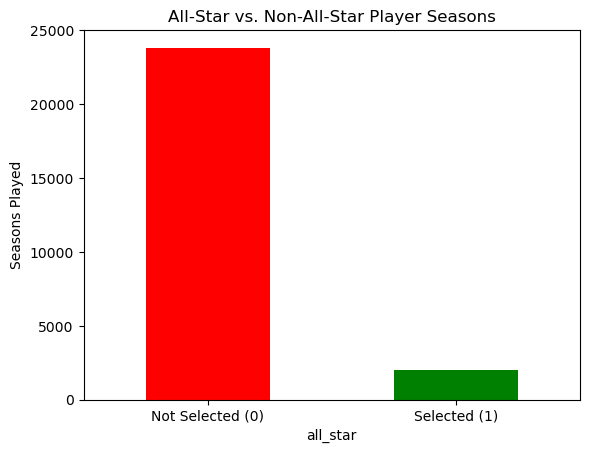

In [9]:
print(f"Player Seasons (total): {len(player_seasons)}")
print(f"All-Star Rate: {player_seasons['all_star'].mean():.2%}")

# target distribution
player_seasons["all_star"].value_counts().sort_index().plot(kind="bar", color=["red", "green"])
plt.title("All-Star vs. Non-All-Star Player Seasons")
plt.xticks([0,1], ["Not Selected (0)", "Selected (1)"], rotation=0)
plt.ylabel("Seasons Played")
plt.show()

As we can see above, of the 25,817 total player seasons, 1,999 (7.7%) are all-star selections. This plot is evidence that precision, recall, and f1 are the most important metrics, as a model that predicts zero all-star selections would technically be about 92.3% accurate.

### **Key Statistics Distribution**

Now we will create histograms of key statistics amongst all player seasons, seperating all-stars from non-all-stars and seeing where the biggest and smallest differences exist.

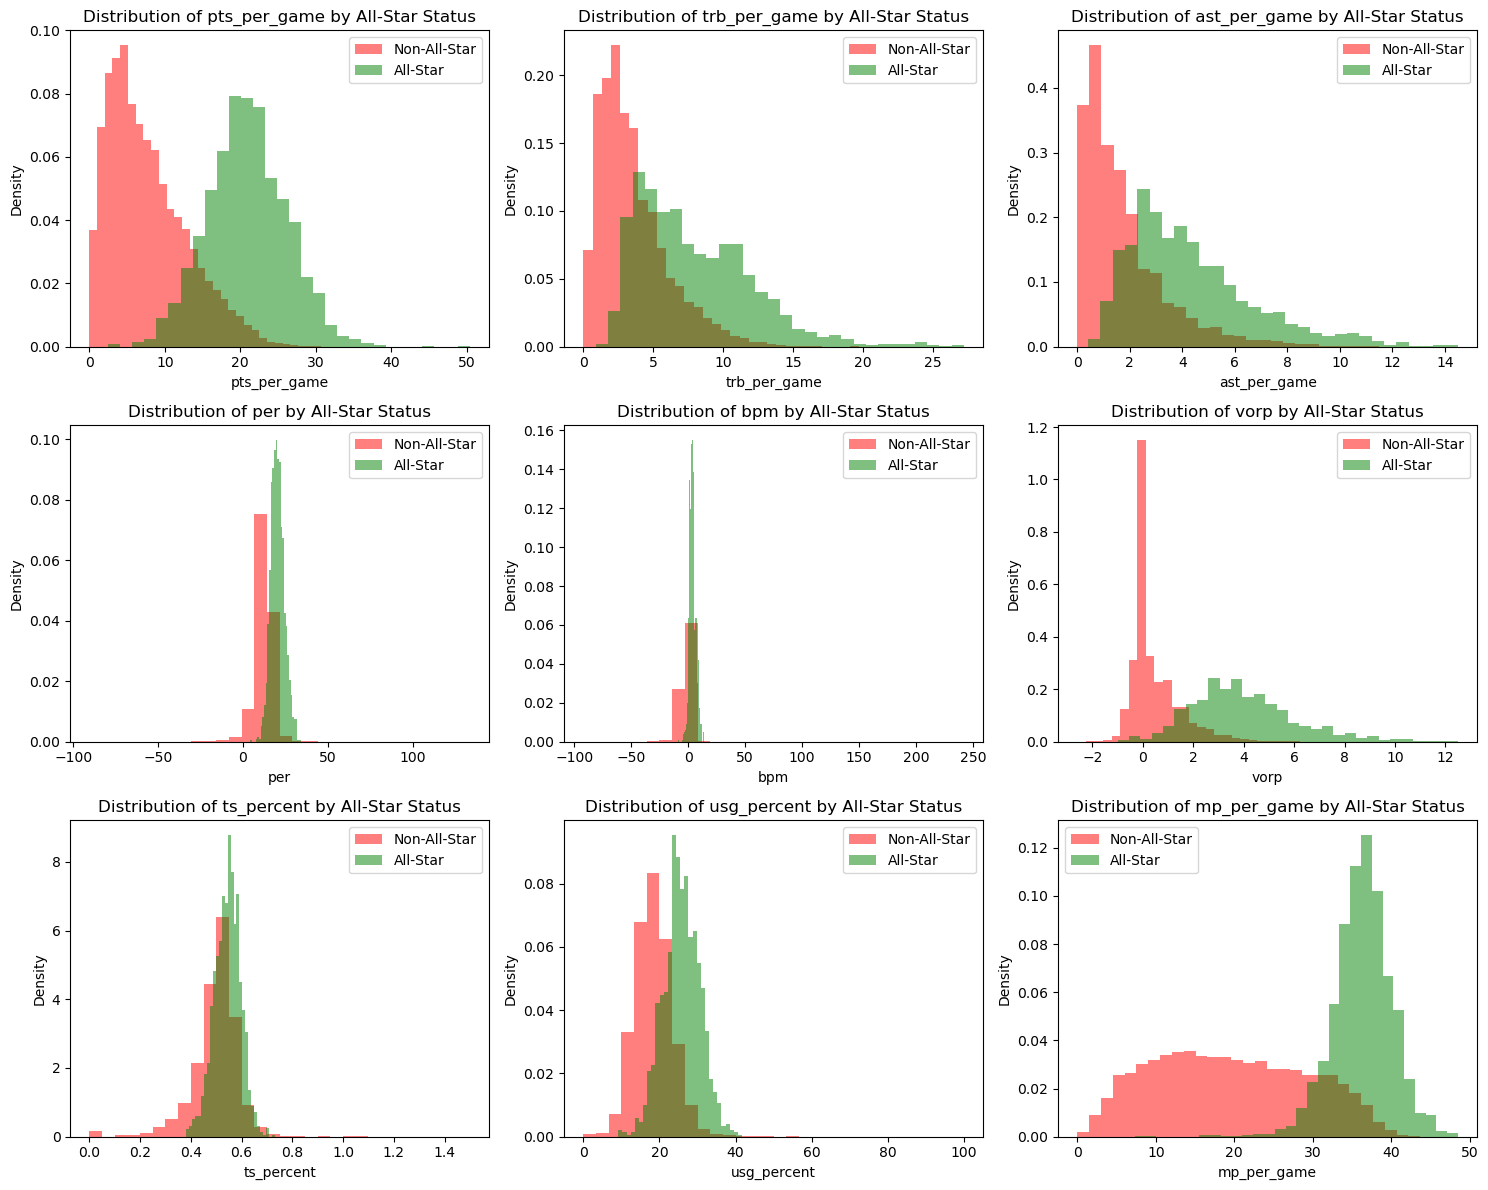

In [10]:
# creating a for loop
imp_stats = ["pts_per_game", "trb_per_game", "ast_per_game", "per", "bpm", "vorp", "ts_percent", "usg_percent", "mp_per_game"]

# setting up ax
fig, axes = plt.subplots(3, 3, figsize=(15,12))
axes = axes.ravel()

for ax, stat in zip(axes, imp_stats):
  # ensuring each row has the stats
  data = player_seasons[[stat, "all_star"]].dropna()
  ax.hist(data.loc[data["all_star"] == 0, stat], bins = 30, alpha = 0.5, color = 'red', density = True, label = 'Non-All-Star')
  ax.hist(data.loc[data["all_star"] == 1, stat], bins = 30, alpha = 0.5, color = 'green', density = True, label = 'All-Star')
  ax.set_title(f"Distribution of {stat} by All-Star Status")
  ax.set_xlabel(stat)
  ax.set_ylabel("Density")
  ax.legend()

plt.tight_layout()
plt.show()

##### **Points Per Game**
Non-all-stars cluster around 2-12 points, whereas the all-stars center out around 18-22 points. This is one of the strongest seperators out of these plots.
##### **Rebounds Per Game**
Both groups exhibit a strong right skew. All-stars peak around 6-8 rebounds, and non-all-stars peak around 3. The overlap here is pretty large though, so this may not be a great seperator.
##### **Assists Per Game**
Non-all-stars peak around only 1-2 assists, rarely eclipsing more than 5-6. All-stars on the other hand have a much stronger right skew, and there is a noticable seperation past 3+ assists.
##### **PER**
Both groups center around 10-20 in terms of player efficiency rating, however a few outlier values strech the x-axis. We will likely clip the axis before building any models to see more differentiation in PER.
##### **BPM**
The Box +/- rate statistic has the same issue as PER, where the boundaries are currently a bit too wide. All-stars do sit more to the right, exhibiting higher +/- scores, however the overlap is heavy.
##### **VORP**
The value over replacement player metric distribution is extremely lopsided. Non-all-stars sit at mostly zero, exhibiting little to no value vs. a replacement player, whereas all-stars have a higher positive spread showing their value over the average player.
##### **TS%**
The true shooting percentage for both groups is around 0.5-0.6, with a few outliers around each end. The fact that the overlap is as strong as it is however may prove that efficiency may not be as important as raw production in terms of all-star selections.
##### **Usage %**
Both groups center around 20-25 percent, with all-stars being a bit higher. Again however there exists much overlap, which keeps the consistency of effiency metrics being slightly undervalued true.
##### **MPG**
This is by far the biggest seperator, as non-all-stars spread completely from 0-35 minutes, whereas all-stars concentrate between 30-40. This makes sense, as having more minutes to play in a game usually leads to higher production.
##### **EDA Summary**
Overall, scoring, minutes, and VORP look to be the strongest seperators of all-stars from non-all-stars. Effiency metrics like shooting percentages and usage overlap pretty heavily on the other hand, possibly being weaker seperators, and some have extreme outliers that hide distribution.

## **Data Preprocessing**

### **Missing Values by Season**

We will start the preprocessing section by handling missing values in seasons.

Columns with missing values: 37
age: first data in 1947
mp: first data in 1952
per: first data in 1952
ts_percent: first data in 1947
x3p_ar: first data in 1968
f_tr: first data in 1947
orb_percent: first data in 1972
drb_percent: first data in 1972
trb_percent: first data in 1968
ast_percent: first data in 1965
stl_percent: first data in 1973
blk_percent: first data in 1972
tov_percent: first data in 1968
usg_percent: first data in 1968
ows: first data in 1947
dws: first data in 1947
ws: first data in 1947
ws_48: first data in 1952
obpm: first data in 1974
dbpm: first data in 1974
bpm: first data in 1974
vorp: first data in 1974
gs: first data in 1977
mp_per_game: first data in 1952
fg_percent: first data in 1947
x3p_per_game: first data in 1968
x3pa_per_game: first data in 1968
x3p_percent: first data in 1968
x2p_percent: first data in 1947
e_fg_percent: first data in 1947
ft_percent: first data in 1947
orb_per_game: first data in 1968
drb_per_game: first data in 1968
trb_per_game: f

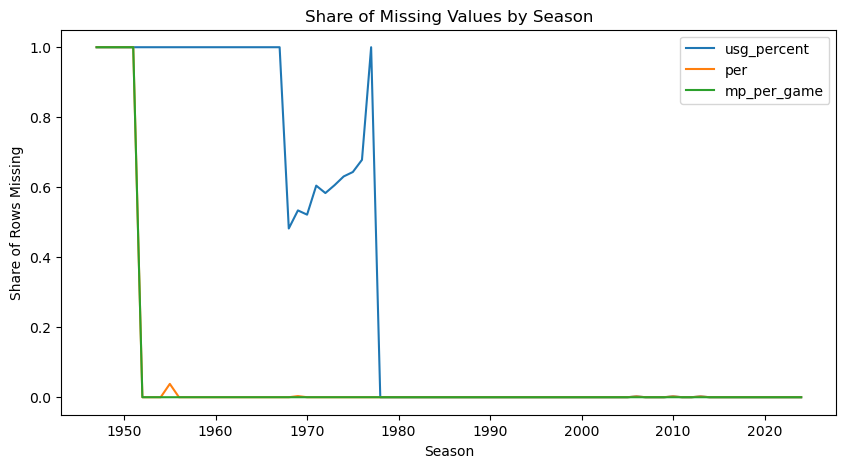

In [11]:
# cols with 1+ missing val
missing_cols = []
for col in player_seasons.columns:
  if player_seasons[col].isna().any():
    missing_cols.append(col)
print(f"Columns with missing values: {len(missing_cols)}")

# share of rows missing each col
missing_rate = player_seasons[missing_cols].isna().groupby(player_seasons['season']).mean()

# first szn
for col in missing_cols:
  first = player_seasons.loc[player_seasons[col].notna(), 'season'].min()
  print(f"{col}: first data in {first}")

# plotting cols with big gaps
fig, ax = plt.subplots(figsize=(10, 5))
for col in ['usg_percent', 'per', 'mp_per_game']:
  ax.plot(missing_rate.index, missing_rate[col], label=col)
ax.set_title("Share of Missing Values by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Share of Rows Missing")
ax.legend()
plt.show()

Looking at the numbers and the plot we can determine a few things based off of the years:
- 1947: basic and win-stats such as ws, ows, dws, ts_percent, fg_percent, and age all have gaps, mostly being scattered.
- 1952: per, mp, mp_per_game, ws_48 begin here, absent beforehand.
- 1965-1968: shooting and rebounding rates
- 1972-1974: defensive and steal/block rates
- 1977: gs

The biggest takeaway is that most gaps come from earlier eras when some statistics weren't recorded. Usage percentage for example is missing for nearly all seasons before 1968, and the BPM/VORP began in 1974. For the ease of this project, we will choose **1980** as the cutoff year for our model as it encompasses more than enough statistical measures for our models to go off of. It also marks the start of the 3-point line era, while avoiding early-season gaps. Statistics are full-season and not yet restricted to pre-break games; see the conclusion for further explanation and effect on results. 

In [12]:
model_data = player_seasons[player_seasons['season'] >= 1980].reset_index(drop = True)
print(f"Model Data (1980+): {model_data.shape}")
print(model_data['all_star'].value_counts())

Model Data (1980+): (19398, 56)
all_star
0    18270
1     1128
Name: count, dtype: int64


Our model now has 19,398 player seasons to work with, 1,128 of which were all-star selection seasons. Next up we will deal with outliers.

### **Outliers**

In [13]:
outlier_stats = ['per', 'bpm', 'ts_percent', 'usg_percent', 'vorp']
print(model_data[outlier_stats].describe().round(2))

# checking extrmeme PER rows (could come from low-min players)
top_per = model_data.sort_values('per', ascending=False).head(10)
print(top_per[['player', 'season', 'mp_per_game', 'per']])

            per       bpm  ts_percent  usg_percent      vorp
count  19395.00  19398.00    19337.00     19395.00  19398.00
mean      12.80     -1.66        0.52        18.85      0.64
std        6.13      4.91        0.09         5.48      1.36
min      -90.60    -92.10        0.00         0.00     -2.60
25%        9.90     -3.40        0.48        15.20     -0.10
50%       12.90     -1.40        0.52        18.50      0.10
75%       15.90      0.60        0.56        22.10      1.00
max      133.80    242.20        1.50       100.00     12.50
                player  season  mp_per_game    per
8516   Naz Mitrou-Long    2018          1.0  133.8
10520  DeAndre Liggins    2014          1.0  129.1
18441    Jackie Butler    2005          1.7   90.3
17147      Steven Hill    2009          2.0   88.3
8671           Zhou Qi    2019          1.0   80.4
7315      Ian Lockhart    1991          2.0   76.3
10665      Ahmad Caver    2022          1.0   76.2
16236    Tyson Wheeler    1999          3.0

We did two things here, we started by checking outliers and other statistical values for efficiency metrics which may be littered with outliers due to high/low minutes played. For PER, the middle 50% of player seasons falls between 9.9 and 15.9 however the maximum is 133.8. BPM also has a similar case, as it's total range is from -92.1 to 242.2 even thought it's 50% is between -3.4 and 0.6. TS% and usage % have values at their edges as well, like 0.0 and 100.0, even though their averages are more centralized.

Specifically for PER, we displayed the top 10 players with the highest PER values. As you can see above, all 10 of these players had 3 or less minutes played. These values are real statistics however they describe very small samples, so they may cause some swinging in the model's preferences.

We have decided to keep these rows in the dataset however. Removing them would need a stronger reason beyond their size, and our models should be able to place enough emphasis on other values that may be stronger at predicting all-stars to outweigh any reason to remove these rows. The model most affected by this is logistic regression, which we will revisit in that section.

### **Feature Selection**

Now we will build the list of features and select our target variable. We will include 44 features out of the 56 total columns within model_data. The exclusions are:
- ID columns
  - `seas_id`, `season`, `player_id`, `player`, `lg`, `pos`, `tm`
- Season Totals
  - `mp`, `ws`, `ows`, `dws`
- Target Variable (y)
  - `all_star`

In [14]:
feature_cols = [
    'age', 'experience', 'g', 'gs', 'mp_per_game', 'per', 'ts_percent', 'x3p_ar', 'f_tr', 'orb_percent', 'drb_percent', 'trb_percent', 'ast_percent', 'stl_percent', 'blk_percent', 'tov_percent', 'usg_percent', 'ws_48', 'obpm', 'dbpm', 'bpm', 'vorp', 'fg_per_game', 'fga_per_game', 'fg_percent', 'x3p_per_game', 'x3pa_per_game', 'x3p_percent', 'x2p_per_game', 'x2pa_per_game', 'x2p_percent', 'e_fg_percent', 'ft_per_game', 'fta_per_game', 'ft_percent', 'orb_per_game', 'drb_per_game', 'trb_per_game', 'ast_per_game', 'stl_per_game', 'blk_per_game', 'tov_per_game', 'pf_per_game', 'pts_per_game'
]

# assigning
X = model_data[feature_cols]
y = model_data['all_star']

print(f"Features: {len(feature_cols)}")
missing = X.isna().sum()
print(missing[missing > 0])

Features: 44
gs               547
per                3
ts_percent        61
x3p_ar            69
f_tr              69
orb_percent        3
drb_percent        3
trb_percent        3
ast_percent        3
stl_percent        3
blk_percent        3
tov_percent       51
usg_percent        3
ws_48              3
fg_percent        69
x3p_percent     2794
x2p_percent      116
e_fg_percent      69
ft_percent       645
dtype: int64


As we can see in our features, there are some missing values that need to be dealt with.
- 3 rows are missing advanced stats, and since it's only 3 rows we will drop them.
- Percentages are missing in some cases (if someone doesn't take a shot, they have no percentage). We can fill them with 0, since the 'attempted' rows will also be 0. The model will be able to tell apart 'no attempts' from '0% made' because of this.
- gs (games started) has 547 missing values, since the stat wasn't always recorded. We can go ahead and drop this statistic as minutes per game is a stronger tell and the model will be able to work with the data using minutes per game better. Our new amount of variables will be 43.

In [15]:
# updating feature cols (removing gs) + reassigning
feature_cols = [
    'age', 'experience', 'g', 'mp_per_game', 'per', 'ts_percent', 'x3p_ar', 'f_tr', 'orb_percent', 'drb_percent', 'trb_percent', 'ast_percent', 'stl_percent', 'blk_percent', 'tov_percent', 'usg_percent', 'ws_48', 'obpm', 'dbpm', 'bpm', 'vorp', 'fg_per_game', 'fga_per_game', 'fg_percent', 'x3p_per_game', 'x3pa_per_game', 'x3p_percent', 'x2p_per_game', 'x2pa_per_game', 'x2p_percent', 'e_fg_percent', 'ft_per_game', 'fta_per_game', 'ft_percent', 'orb_per_game', 'drb_per_game', 'trb_per_game', 'ast_per_game', 'stl_per_game', 'blk_per_game', 'tov_per_game', 'pf_per_game', 'pts_per_game'
]
X = model_data[feature_cols]
y = model_data['all_star']

# dropping the 3 players with no advanced stats
model_data = model_data.dropna(subset=['per']).reset_index(drop=True)

# filling '0's into shooting percentages for players w/ no attempts
pct_cols = ['ts_percent', 'x3p_ar', 'f_tr', 'tov_percent', 'fg_percent', 'e_fg_percent', 'x3p_percent', 'x2p_percent', 'ft_percent']
model_data[pct_cols] = model_data[pct_cols].fillna(0)

# total amount of missing values in feature columns
print(model_data[feature_cols].isna().sum().sum())

0


There are now 0 missing values in our feature columns within our model, so we can begin scaling.

### **Scaling**

Now we will build the logisitc regression pipeline using scaling. We do this as logisitic regression is sensitive to feature scale, so each predictor will be standardized to mean 0 and SD 1.

In [16]:
# building scaler
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])
print(logistic_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000))])


## **Train-Test Split**

Now we will split the data into an 80/20 percent train & test split.

In [17]:
# assigning features + target for split
X = model_data[feature_cols]
y = model_data['all_star']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size = 0.2,
                                                    stratify = y,
                                                    random_state = 42)

print(f"Training Features: {X_train.shape}")
print(f"Test Features: {X_test.shape}")

Training Features: (15516, 43)
Test Features: (3879, 43)


There are now 15,516 player seasons for the models to work with in the training set, containing all 43 of the features, with a test set of 3,879 player seasons for testing. One thing to check before model construction is that the all-star rate is the same in all three sets as well.

In [18]:
# checking proporrtion
all_prop = y.value_counts(normalize=True).sort_index()
train_prop = y_train.value_counts(normalize=True).sort_index()
test_prop = y_test.value_counts(normalize=True).sort_index()
print(pd.DataFrame({"all": all_prop, "train": train_prop, "test": test_prop}).round(4))

             all   train    test
all_star                        
0         0.9418  0.9419  0.9417
1         0.0582  0.0581  0.0583


The split is correctly stratified, as the all-star share is 5.82% in the entire model data, and is split 5.81% & 5.83% in training and test respectively. The fact that the total rate in the model data is lower than the original 7.7% checks out, since we removed rows prior to our 1980 cutoff that contained all-star selections.

## **Model Construction**

### **Logistic Regression**

We can now begin constructing our models, starting with logistic regression. We will start by tuning.

#### **Tuning**

We will try 10 iterations of random values of C, where each value will be scored by a 5-fold stratified cross-validation on the training set. The score is F1 for the all-star class. We use F1 instead of accuracy as explained earlier due to the low amount of all-stars in the dataset, and the fact that a model that predicts 0 all-stars would have a high accuracy but be a poor model.

In [19]:
# search space
lr_param_space = {
    "model__C": loguniform(1e-3, 1e2),
}

# stratified 5fold CV (only on training)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_search = RandomizedSearchCV(
    estimator=logistic_pipeline,
    param_distributions=lr_param_space,
    n_iter=10,
    scoring="f1",
    cv=cv,
    refit = True,
    return_train_score =True,
    n_jobs =-1,
    random_state=42
)
lr_search.fit(X_train, y_train)

# best params
print(f"Best Parameters: {lr_search.best_params_}")
# best f1
print(f"Best CV F1: {lr_search.best_score_:.4f}")

Best Parameters: {'model__C': 56.69849511478853}
Best CV F1: 0.7286


The best setting was C = 56.7, with a cross validated F1 score of 0.7286. Since C is a bit large, the penalty on the weights is weaker suggesting that the stats carry a fairly strong signal in terms of all-star selections. The model is not over-penalizing the weights, and is able to use the stats to make a better prediction.

#### **Evaluation**

Now we can evaluate the model using our C value of 56.7, and see how it performs on the test set.

            train    test
accuracy   0.9713  0.9709
precision  0.8040  0.7653
recall     0.6685  0.7212
f1         0.7300  0.7426


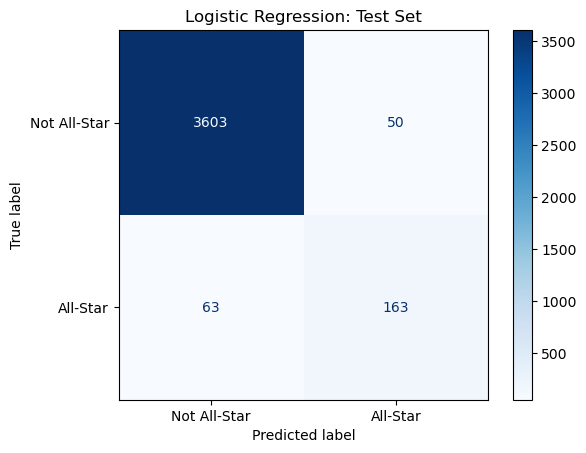

In [20]:
def evaluate(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }

results = pd.DataFrame({
    "train": evaluate(y_train, lr_search.predict(X_train)),
    "test": evaluate(y_test, lr_search.predict(X_test))
}).round(4)
print(results)

# confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, lr_search.predict(X_test), display_labels=["Not All-Star", "All-Star"], cmap="Blues")
plt.title("Logistic Regression: Test Set")
plt.show()

These results look pretty reasonable. F1 is 0.730 on training and 0.743 on test, so they are close enough to suggest that the model is not overfitting. As for the confusion matrix, of the 226 all-stars in the test set, the model caught 163 and missed 63. It also flagged 50 non-all-stars as all-stars. The precision was 0.765 (of the players it flagged as all-stars, about 76.5% were actually all-stars). The recall was 0.721 (it found about 72.1% of the actual all-stars). The accuracy was very high at 97.1%, outperforming the 94.2% you'd get from a model predicting 0 all-stars. Overall, this is a good result for the logistic regression model, and now we will check out the coefficients to see which statistics matter most in terms of all-star selections.

In [21]:
coefs = pd.Series(lr_search.best_estimator_.named_steps["model"].coef_[0], index=feature_cols)
coefs = coefs.sort_values(key = abs, ascending=False)
print(coefs.head(10).round(3))

ws_48           4.037
per            -3.678
usg_percent     1.947
ft_per_game    -1.697
fta_per_game    1.667
ft_percent      1.505
ts_percent     -1.362
mp_per_game     1.165
trb_percent     1.137
fg_per_game     1.057
dtype: float64


The largest standardized coefficient is for win shares per 48 minutes (about 4.0), so it has the strongest association with all-star selections. PER has a large negative coefficient, and free throw attempts / makes have opposite signs of each other. Minutes, usage, rebounds, and field goals per game all have positive coefficients. Now that the logistic regression model has been built and evaluated, we will move on to the next model, random forest, and evaluate the logistic regression model later compared to the other models.

### **Random Forest**

#### **Tuning**

Random forest doesn't need scaling, so we can skip that step and immediately begin with creating the pipeline and the rest of the tuning.

In [22]:
# random forest pipeline
rf_pipeline = Pipeline([
    # doesn't need scaling, can just pass through the features
    ('scaler', 'passthrough'),
    ('model', RandomForestClassifier(random_state=42))
])

# search space
rf_param_space = {
    "model__n_estimators": [100, 200, 400],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_leaf": [1, 5, 10],
    "model__max_features": ["sqrt", "log2", 1.0]
}

# stratified 5fold CV (only on training)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_space,
    n_iter=10,
    scoring="f1",
    cv=cv,
    refit = True,
    return_train_score =True,
    n_jobs =-1,
    random_state=42
)
# fitting
rf_search.fit(X_train, y_train)

print(f"Best Parameters: {rf_search.best_params_}")
print(f"Best CV F1: {rf_search.best_score_:.4f}")

Best Parameters: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': None}
Best CV F1: 0.7026


The search tried 10 random combinations of the number of trees, max depth, minimum samples per leaf, and the numnber of features to consider at each split. The best setting was 200 trees, unlimited depth, 1 minimum sample per leaf, and log2 features per split with a F1 score of 0.7026. That's slightly less than the logisitic regressions, so a simple linear model currently does slightly better on the data so far. We will now evaluate the random forest model on the test set and see how it performs.

#### **Evaluation** 

           train    test
accuracy     1.0  0.9714
precision    1.0  0.7979
recall       1.0  0.6814
f1           1.0  0.7351


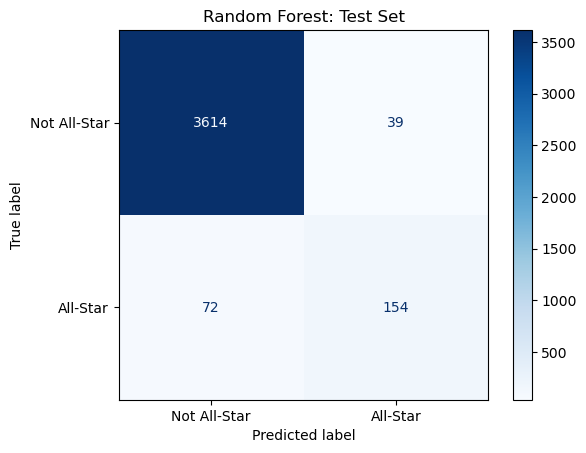

In [23]:
rf_results = pd.DataFrame({
    "train": evaluate(y_train, rf_search.predict(X_train)),
    "test": evaluate(y_test, rf_search.predict(X_test))
}).round(4)
print(rf_results)

# confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, rf_search.predict(X_test), display_labels=["Not All-Star", "All-Star"], cmap="Blues")
plt.title("Random Forest: Test Set")
plt.show()

On the test set, the tuned forest reached an accuracy of 0.971, a precision of 0.798, a recall of 0.681, and an F1 of 0.735 for the all-star class. Training performance was perfect with scores of 1.0 throughout, showing clear overfitting even after tuning. The confusion matrix shows 154 of 226 all-stars were caught, with 39 false positives. Next we will check out feature importance to see which statistics mattered most in the random forest model.

#### **Feature Importance**

In [24]:
def feature_importance_table(model, feature_names):
    return (pd.Series(model.feature_importances_, index=feature_names, name = "Importance").sort_values(ascending=False))
rf_importance = feature_importance_table(rf_search.best_estimator_.named_steps["model"], feature_cols)
print(rf_importance.head(10).round(3))

vorp            0.100
pts_per_game    0.087
fg_per_game     0.062
bpm             0.051
per             0.049
fta_per_game    0.047
mp_per_game     0.043
ws_48           0.038
obpm            0.038
ft_per_game     0.038
Name: Importance, dtype: float64


The top features for the random forest model were VORP (0.100), points per game (0.087), field goals per game (0.062), BPM (0.051), and PER (0.049). Several of these match our earlier EDA, as the points and minutes played seperated all-stars pretty clearly. Importance is spread across many statistics, however, and the model is able to use a combination of stats to make a better prediction than just one or two statistics alone. Next we will move on to the AdaBoost model.

### **Adaptive Boosting (AdaBoost)**

#### **Tuning**

Now we will build out the AdaBoost model, starting with tuning again.

In [25]:
# adaboost pipeline, again no scaling needed
ada_pipeline = Pipeline([
    ('scaler', 'passthrough'),
    ('model', AdaBoostClassifier(algorithm='SAMME', random_state=42))
])

# search space
ada_param_space = {
    "model__n_estimators": [50, 100, 200, 400],
    "model__learning_rate": loguniform(0.01, 1.0),
}

# startified 5fold CV (only on training)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

ada_search = RandomizedSearchCV(
    estimator=ada_pipeline,
    param_distributions= ada_param_space,
    n_iter=10,
    scoring="f1",
    cv=cv,
    refit = True,
    return_train_score =True,
    n_jobs =-1,
    random_state=42
)
ada_search.fit(X_train, y_train)

print(f"Best Parameters: {ada_search.best_params_}")
print(f"Best CV F1: {ada_search.best_score_:.4f}")

Best Parameters: {'model__learning_rate': 0.15751320499779725, 'model__n_estimators': 200}
Best CV F1: 0.6998


The search tried 10 random combinations of the number of boosting rounds and learning rate using single-split trees as weaker learners. The best setting was 200 rounds with a learning rate of about 0.158, giving an F1 score of 0.6998. That's the lowest so far of all three models, and we will now evaluate the model on the test set to see how it performs.

#### **Evaluation**

            train    test
accuracy   0.9691  0.9667
precision  0.7772  0.7366
recall     0.6574  0.6681
f1         0.7123  0.7007


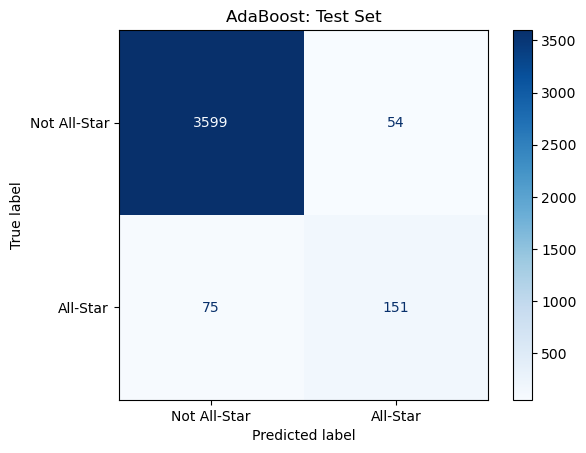

In [26]:
ada_results = pd.DataFrame({
    "train": evaluate(y_train, ada_search.predict(X_train)),
    "test": evaluate(y_test, ada_search.predict(X_test))
}).round(4)
print(ada_results)

# confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, ada_search.predict(X_test), display_labels=["Not All-Star", "All-Star"], cmap="Blues")
plt.title("AdaBoost: Test Set")
plt.show()

On the test set the tuned AdaBoost model reached an accuracy of 0.967, a precision of 0.737, a recall of 0.668, and an F1 of 0.701 for the all-star class. The model isn't overfitting much, as the training and testing F1 scores weren't super far off from one another. The confusion matrix shows 151 of 226 all-stars were caught, with 54 false positives. AdaBoost is the lowest performing model so far, and we will now move on to the final model, XGBoost.

### **Extreme Gradient Boosting (XGBoost)**

#### **Tuning**

Now we will begin tuning the final model, the XGBoost model.

In [27]:
# xgboost pipeline, again no scaling needed
xgb_pipeline = Pipeline([
    ('scaler', 'passthrough'),
    ('model', XGBClassifier(eval_metric='logloss', random_state=42))
])

# search spcace
xgb_param_space = {
    "model__n_estimators": [100, 200, 400],
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__max_depth": [3, 4, 5, 6],
    "model__subsample": [0.6, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0]
}

# stratified 5fold cv (only training)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions= xgb_param_space,
    n_iter=10,
    scoring="f1",
    cv=cv,
    refit = True,
    return_train_score =True,
    n_jobs =-1,
    random_state=42
)
xgb_search.fit(X_train, y_train)

print(f"Best Parameters: {xgb_search.best_params_}")
print(f"Best CV F1: {xgb_search.best_score_:.4f}")

Best Parameters: {'model__colsample_bytree': 0.6, 'model__learning_rate': 0.01700037298921102, 'model__max_depth': 5, 'model__n_estimators': 400, 'model__subsample': 1.0}
Best CV F1: 0.7257


The search tried 10 random combinations of the number of trees, tree depth, learning rate, and the share of rows and features used per tree. The best setting was 400 trees, a max depth of 5, learning rate of about 0.017, 60% of featuyres per tree, and all rows per tree, with a F1 of 0.7257. That's essentially tied with logisitic regression, and ahead of the forest and AdaBoost models. We will now evaluate the model on the test set to see how it performs.

#### **Evaluation**

            train    test
accuracy   0.9864  0.9727
precision  0.9368  0.8030
recall     0.8215  0.7035
f1         0.8754  0.7500


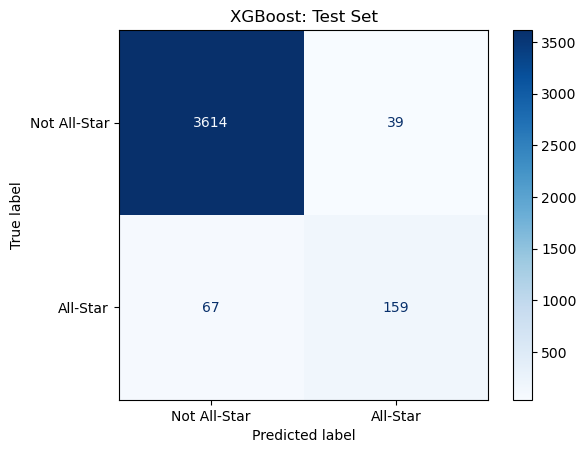

In [28]:
xgb_results = pd.DataFrame({
    "train": evaluate(y_train, xgb_search.predict(X_train)),
    "test": evaluate(y_test, xgb_search.predict(X_test))
}).round(4)
print(xgb_results)

# confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, xgb_search.predict(X_test), display_labels=["Not All-Star", "All-Star"], cmap="Blues")
plt.title("XGBoost: Test Set")
plt.show()

On the test set, the tuned XGBoost model reached an accuracy of 0.973, a precision of 0.803, a recall of 0.704, and an F1 of 0.750. It's training F1 was 0.875, so it fits the training players more closely than the other models do, but the test F1 still held up. The confusion matrix shows 159 of 226 all-stars were caught, with 39 false positives. The margin over logisistic regression is small (0.743), so the replicated runs in the upcoming model eval will show whether the difference holds up.

## **Model Evaluation**

All four models have now been tuned and evaluated on the same split. The next step is to put them side by side to compare their performance and see which one is the best fit for predicting all-stars.

#### **Comparison of Models**

In [29]:
summary = pd.DataFrame({
    "Logistic Regression": evaluate(y_test, lr_search.predict(X_test)),
    "Random Forest": evaluate(y_test, rf_search.predict(X_test)),
    "AdaBoost": evaluate(y_test, ada_search.predict(X_test)),
    "XGBoost": evaluate(y_test, xgb_search.predict(X_test))
}).T.round(4)
print(summary)

                     accuracy  precision  recall      f1
Logistic Regression    0.9709     0.7653  0.7212  0.7426
Random Forest          0.9714     0.7979  0.6814  0.7351
AdaBoost               0.9667     0.7366  0.6681  0.7007
XGBoost                0.9727     0.8030  0.7035  0.7500


All four models performed pretty similar on the single split. XGBoost had the highest accuracy (0.973), precision (0.803), and F1 (0.750). Logistic regression had the highest recall (0.721) and the second highest F1 (0.743). Random forest's precision (0.798) was close to XGBoost's, but it found fewer all-stars (recall of 0.681). AdaBoost had the lowest F1 (0.701) and recall (0.668). The F1 spread across the four models is about 0.05, and the test set contains only 226 all-stars, so a handful of players can shift the ranking pretty easily. We can't call a winner from just one split, which is why replicated runs are needed to see if the differences hold up.

#### **Replication Function**

Our next step is the seed replication. We will use 10-seeds (originally we planned on using 30, however due to computational/time constraints, we will use 10). Each seed gets a new stratified split, and the full process runs again for every model:
- Tune with cross-validation on the training set
- Evaluate on the seed's test set
- Record the results
- Report the mean, sd, min and max for each metric

In [ ]:
def run_replicates(pipeline, param_space, n_seeds=10, base_seed=100):
    rows = []
    for seed in range(base_seed, base_seed + n_seeds):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    
        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=param_space,
            n_iter=10,
            scoring="f1",
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=seed),
            refit=True,
            n_jobs=-1,
            random_state=seed
        )
        search.fit(X_tr, y_tr)
        rows.append(evaluate(y_te, search.predict(X_te)))
    return pd.DataFrame(rows)

Now we can run this replication on all four models and see how they perform across multiple splits.

#### **Running Replication**

##### **Logistic Regression Replication**

In [31]:
lr_rep = run_replicates(logistic_pipeline, lr_param_space, n_seeds=10, base_seed=100)
print("Logistic Regression")
print(lr_rep.agg(["mean", "std", 'min', 'max']).T.round(4))

Logistic Regression
             mean     std     min     max
accuracy   0.9704  0.0027  0.9655  0.9742
precision  0.7988  0.0270  0.7538  0.8596
recall     0.6584  0.0453  0.5708  0.7345
f1         0.7210  0.0311  0.6582  0.7685


Across 10 random splits, the logistic regression model averaged an F1 of 0.721 for the all-star class, with an SD of 0.031 and a range of 0.658 to 0.769. The precision averaged 0.799 and recall 0.658. Accuracy was stable, averaging 0.970 with an SD of only 0.003. The single split F1 of 0.743 came out above the replicated average, so that result was on the more hopeful side of the distribution. 
 
Given the strong precision, the model's flagged 'all-stars' are consistenly correct (to an extent) however the recall being lower means it misses a fair amount of them. Some of these misses could be due to other factors around all-star selections that the model doesn't have access to, like fan voting, injuries, or other intangibles. This will likely exist in the other models as well, and is a limitation of the data and model that will be discussed more towards the end of this project.
 
The spread between splits shows that single-split differences can be misleading. However, overall, the logistic regression model performed reasonably well.

##### **Random Forest Replication**

In [32]:
rf_rep = run_replicates(rf_pipeline, rf_param_space, n_seeds=10, base_seed=100)
print("Random Forest")
print(rf_rep.agg(["mean", "std", 'min', 'max']).T.round(4))

Random Forest
             mean     std     min     max
accuracy   0.9688  0.0021  0.9647  0.9711
precision  0.7903  0.0330  0.7619  0.8654
recall     0.6345  0.0375  0.5708  0.7080
f1         0.7029  0.0230  0.6532  0.7339


Random forest averaged an F1 of 0.703 across the 10 splits with a standard deviation of 0.023 and a range of (0.653, 0.734). Precision averaged 0.790 and recall 0.635. Accuracy was stable again and high, averaging 0.969. Most players flagged were truly all-stars like logistic regression, however the even lower recall continues to show that the model(s) are missing a fair amount of all-stars. The single split F1 (0.735) was as optimistic as the logistic regression model as well. The forest however does fit the training data extremely well, which suggests it may be memorizing the training data and not generalizing as well to unseen data. This is a common issue with random forests and should be expected and considered when evaluating/choosing a model.

##### **AdaBoost Replication**

In [33]:
ada_rep = run_replicates(ada_pipeline, ada_param_space, n_seeds=10, base_seed=100)
print("AdaBoost")
print(ada_rep.agg(["mean", "std", 'min', 'max']).T.round(4))

AdaBoost
             mean     std     min     max
accuracy   0.9663  0.0025  0.9621  0.9698
precision  0.7520  0.0307  0.7005  0.7944
recall     0.6314  0.0372  0.5708  0.6947
f1         0.6857  0.0263  0.6418  0.7194


Across 10 random splits AdaBoost averaged an F1 of 0.686 with an SD of 0.026 and a range of (0.642 to 0.719). It was the lowest performing model of the four (in terms of F1), with its average precision also low (0.752). Its recall was 0.631, the lowest of the four as well. Accuracy however was once again stable at about 0.966. This model flags players with reasonable reliability however it misses more all-stars than the other models do. This is likely beacuse AdaBoost tends to give more weight to the hardest cases to classify, which is important because all-stars may be selected for untraditional reasons (like fan voting, injuries, etc.) and the boosting focuses on examples that the model can't learn from. This limits generalization and the model's ability to find all-stars.

##### **XGBoost Replication**

In [34]:
xgb_rep = run_replicates(xgb_pipeline, xgb_param_space, n_seeds=10, base_seed=100)
print("XGBoost")
print(xgb_rep.agg(["mean", "std", 'min', 'max']).T.round(4))

XGBoost
             mean     std     min     max
accuracy   0.9690  0.0024  0.9657  0.9724
precision  0.7780  0.0309  0.7393  0.8545
recall     0.6562  0.0421  0.6018  0.7257
f1         0.7110  0.0267  0.6749  0.7540


Across the 10 splits XGBoost averaged an F1 of 0.711 for the all-star class with an SD of 0.027 and a range of (0.675 to 0.754). Its precison was averaged around 0.778 and its recall was averaged around 0.656, so it appears this model is more precise than it is able to completely find all-stars. Its F1 score for the single split (0.750) was the highest of any model on that single split, but the replicated average was lower, proving that first result was pretty optimistic. XGBoost ranks second on replicated F1.

##### **Model Evaluation Summary**

Across 10 random splits, logistic regression had the highest average F1 (0.721), followed by XGBoost (0.711), random forest (0.703), and AdaBoost (0.686). The gaps among the top 3 are about one SD, so they are not significantly off from one another in terms of performance. All four models remained consistently high in accuracy around 0.97, but the recall was varied between 0.63-0.66. This effectively means the models are missing about 1/3 of all-stars, which is likely more of a limitation of the data rather than the models, since the data doesn't include fan voting, injuries, or other intangibles that may affect all-star selections. Precision ranged from around 0.75 to 0.80, and since every model's single split F1 was higher than the replicated averages, it shows the importance of running multiple splits to get a better idea of model performance.

## **Visulization and Reporting**

### **Replicated Test Performance Comparison Visualization**

We will begin our visualization and reporting section by plotting the replicated test performance of each model across the 10 splits. This will allow us to see how each model performed in terms of F1 score, precision, and recall.

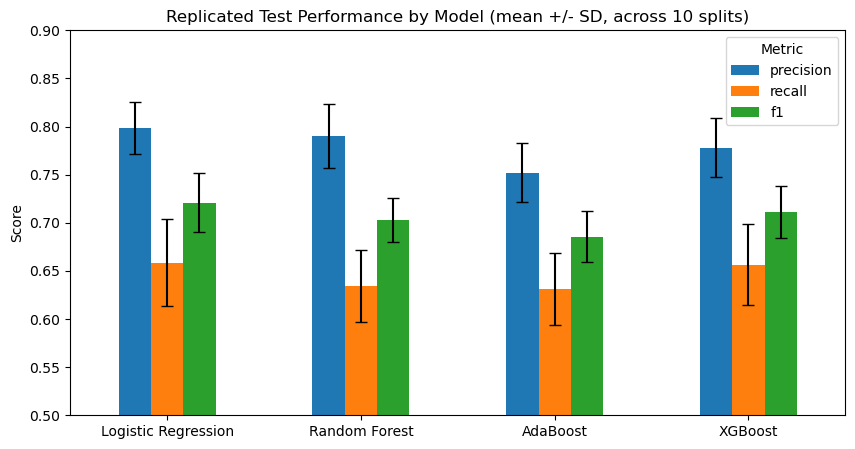

In [36]:
replicates = {
    "Logistic Regression": lr_rep,
    "Random Forest": rf_rep,
    "AdaBoost": ada_rep,
    "XGBoost": xgb_rep
}

# excluding accuracy since its not as informative / remains stable across all 4 of the models
metrics = ["precision", "recall", "f1"]

means = pd.DataFrame({name: df[metrics].mean() for name, df in replicates.items()}).T.round(4)
stds = pd.DataFrame({name: df[metrics].std() for name, df in replicates.items()}).T.round(4)

fig, ax = plt.subplots(figsize=(10, 5))
means.plot(kind="bar", yerr=stds, capsize=4, ax=ax, rot=0)
ax.set_title("Replicated Test Performance by Model (mean +/- SD, across 10 splits)")
ax.set_ylabel("Score")
ax.set_ylim(0.5, 0.9)
ax.legend(title="Metric")
plt.show()

This chart above compares the four models across the splits on our key metrics. The precision seems to be the strongest metric across all four models, whereas the recall is the weakest. F1 falls between the two, with logistic regression exhibiting the highest average F1 score across the splits of all four models. The error bars overlap across models on every single metric, so the differences are not statistically significant.

### **Statistical Importance Visualization**

Now we will create a visualization comparing the top 10 features each of the four models relied on most when making predictions. This will allow us to see which statistics matter most in terms of all-star selections.

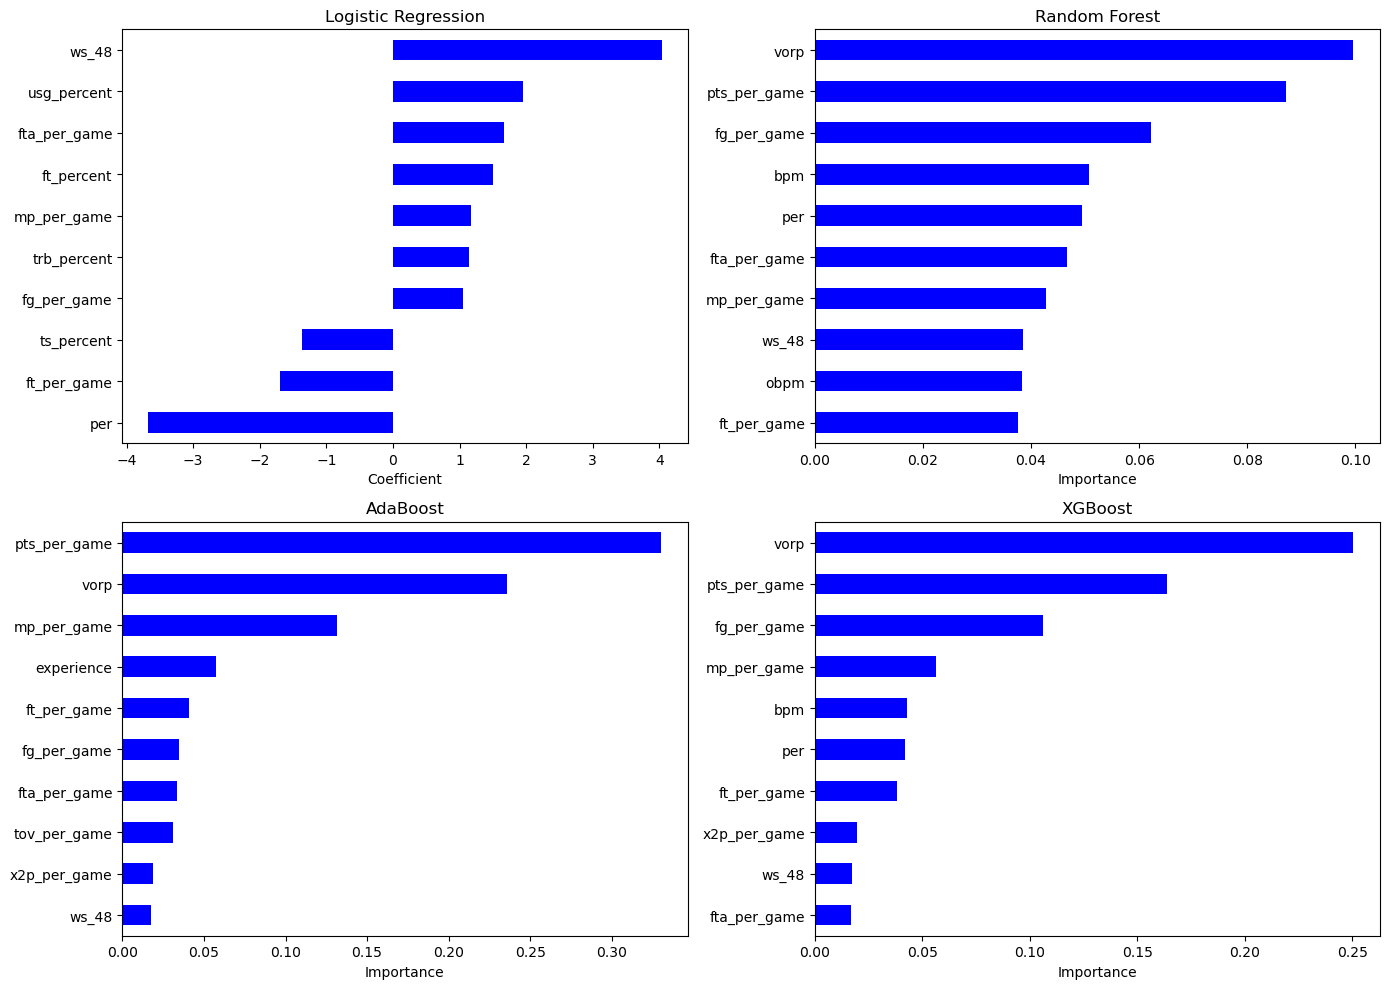

In [42]:
lr_coefs = pd.Series(lr_search.best_estimator_.named_steps["model"].coef_[0], index=feature_cols)
rf_importance = feature_importance_table(rf_search.best_estimator_.named_steps["model"], feature_cols)
ada_importance = feature_importance_table(ada_search.best_estimator_.named_steps["model"], feature_cols)
xgb_importance = feature_importance_table(xgb_search.best_estimator_.named_steps["model"], feature_cols)


top_lr = lr_coefs.reindex(lr_coefs.abs().sort_values(ascending=False).index).head(10).sort_values()
top_rf = rf_importance.head(10).sort_values()
top_ada = ada_importance.head(10).sort_values()
top_xgb = xgb_importance.head(10).sort_values()

panels = [
    ("Logistic Regression", top_lr, "blue", "Coefficient"),
    ("Random Forest", top_rf, "blue", "Importance"),
    ("AdaBoost", top_ada, "blue", "Importance"),
    ("XGBoost", top_xgb, "blue", "Importance")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (title, values, color, xlabel) in zip(axes.ravel(), panels):
    values.plot(kind="barh", ax=ax, color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
plt.tight_layout()
plt.show()

#### **Logistic Regression**
For the logistic regression model, win shares per 48 minutes was the most important statistic (about +4.0), meaning a higher win shares per 48 minutes is strongly associated with all-star selections within the logistic regression model. PER has the largest negative coefficient (about -3.7), which may be because it overlaps heavily with other efficiency statistics (bpm, vorp, etc.) so once in the model, PER's remaining effects tend to point the other direction (towards non-all-star selctions). Usage rate, free throw attempts per game, and free throw percentage were also high positive contributors, likely due to players known as having a "green light" to shoot (detailed by high usage) or players who tend to have a "whistle" drawn on them more frequently due to their ability to draw in defenders (detailed by free throw attempts).
#### **Random Forest**
VORP was the most important statistic for the random forest model (about 0.10) folowed by points per game (about 0.09), BPM (0.05) and field goals per game (0.06). Win shares per 48 minutes is ironically near the bottom of the top 10 features, which is interesting because it was the most important statistic for the logistic regression model.
#### **AdaBoost**
Points per game was the strongest statistic for the AdaBoost model (about 0.33) followed by VORP (0.24) and minutes per game (about 0.13). Experience shows up towards the bottom which is a bit surprising as it isn't neccesarily a performance metric, but it may be that the model is picking up on the fact that players with more experience are more likely to be all-stars (longer careers, more exposure, etc.).
#### **XGBoost**
VORP is the highest for XGBoost (about 0.25), then points per game (0.16) and field goals per game (0.10).
#### **Statistical Importance Summary**
Overall, across all four models VORP and points per game were the most consistently important statistics used by the models to predict all-star selections. The boosted models relied on them a bit more heavily than the other models as well. The stats that show up in all four models consistently are free throws and field goal related, as well as minutes and win shares per 48 minutes. These were important no matter which model was used.

## **Summary & Closing Remarks**

### **Revisiting the Main Questions**

As a reminder, this project set out to answer three questions:
1. Which model best seperates all-stars from other players?
2. Which statistics matter most in terms of all-star selections?
3. Where do the models disagree with actual selections, and why might this happen?

#### **1. Which model best seperates all-stars from other players?**

Logistic regression had the highest average F1 score across the 10 replicated splits, followed by XGBoost, random forest, and AdaBoost. The gap between logistic regression and the other top 2 models were about one standard deviation, so the top 3 models were close. Logistic regression also happens to be the simplest model of the four, and yet performed as well as or better than the more complex tree-based models, so it is the model we would recommend for predicting all-stars based on both performance and simplicity. All four models had high and consistent accuracy, but accuracy alone can be misleading especially in this case as a model that never predicts an all-star (using the model data) would still score about 94%.

#### **2. Which statistics matter most in terms of all-star selections?**

Across the models, the strongest signals were volume and production statistics rather than efficiency metrics. This checks out as all-star selections tend to involve high-producing players who put up raw numbers potentially at the sacrifice of efficiency (although many are still efficient players). Points per game and value over replacement player (VORP) were the most important features for the forest and booster models, however for logistic regression the win shares per 48 minutes metric and PER were the higher weighted statistics. Five statistics appeared in all four models top 10 (free throws per game, field goals per game, free throw attempts per game, minutes per game, and win shares per 48 minutes). 

#### **3. Where do the models disagree with actual selections, and why might this happen?**

Recall was the weakest metric across every model (averaging between 0.63-0.66) meaning that the models were missing about 1/3 of the all-stars , while the precision was higher (averaging between 0.75-0.80). These misses are likely due to the fact that the data doesn't include fan voting, injuries, or other intangibles that may affect all-star selections. For example, a player who regularly makes the all-star game might continue to be selected even in down years where their performance may not be as strong as a typical all-star season. The models are able to find the players who are statistically deserving of all-star selections, but they can't account for the other factors that may lead to a player being selected or not. This is a limitation of the data and models, and should be considered when interpreting the results.

### **Limitations**

#### **All-Star Selection Process**

The first notable limitation of this project is the timeliness of the data. All-star selections are made just about halfway through the season, and the data used in this project is full-season statistics. This means that the models are using statistics that may not have been available at the time of selection, which could lead to discrepancies between model predictions and actual selections. Players may for example have a strong start to the season and be selected, but then have a down second half of the season that drags their full-season statistics down. The models would then predict that player as a non-all-star based on their full-season statistics, even though they were selected as an all-star based on their first half performance. 

#### **Data Timeline**

The second limitation is the timeline of the data. Our analysis begins in 1980, in which the 3-point era began, so the findings within this project may not be entirely applicable to earlier eras of basketball. Points were scored differently, and the game was played differently, so the models may not be able to accurately predict all-stars from earlier eras.

#### **Feature Correlation & ModelOverfitting**

Another limitation is the fact that many of the features were highly correlated with one another. This makes individual coefficients and importances harder to interpret. For example, a player who scores a lot of points is likely to also have a high usage rate, and a player who has a high usage rate is likely to have a high number of field goal attempts. This makes it difficult to determine which statistic is truly driving the model's predictions. Additionally, the tree-based models (random forest, AdaBoost, and XGBoost) are more prone to overfitting due to their complexity, which can lead to poor generalization on unseen data.

### **Future Steps**

Future steps for this project may include but should not be limited to:
- Using only first-half statistics to predict all-star selections, which would be more timely and relevant
- Using more advanced statistics that may be more predictive of all-star selections, such as player tracking data or advanced shooting metrics
- Adding in outside factors that may affect all-star selections, such as fan voting, injuries, or team success
- Increasing the number of replicated splits to get a more robust estimate of model performance